In [1]:
from src import utils
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Math, clear_output

root = Path.cwd().parent
data_dir = root / "data"

In [2]:
anchors = np.loadtxt(data_dir / "anchorsII.dat")
ranges = np.loadtxt(data_dir / "rangesII.dat")

print(anchors.shape)
print(ranges.shape)

for i in range(3):
    H = utils.hessian(anchors[i], anchors, ranges[0])
    print(f"Anchor {i+1}:")
    print("Hessian =", H)

(3, 2)
(60, 3)
Anchor 1:
Hessian = [[263.69281078   4.        ]
 [  4.          14.01281078]]
Anchor 2:
Hessian = [[ 38.85281078   0.        ]
 [  0.         -60.50718922]]
Anchor 3:
Hessian = [[263.69281078  -4.        ]
 [ -4.          14.01281078]]


In [3]:
C = 2 * (anchors[1:] - anchors[0])

p_LLS_list = []
p_gd_list = []

for t, r in enumerate(ranges):
    d_t = r[0]**2 - r[1:]**2 + np.sum(anchors[1:]**2, axis=1) - np.sum(anchors[0]**2)
    p_LLS_t = utils.naive_LSE(C, d_t)

    p_init = p_LLS_t
    iter_cnt, p_gd_t, final_loss = utils.g_gd(t, p_init, anchors, ranges)
    print(f"t={t+1} | iterations:{iter_cnt}, loss={final_loss}")

    p_LLS_list.append(p_LLS_t)
    p_gd_list.append(p_gd_t)

p_LLS_list = np.array(p_LLS_list)
p_gd_list = np.array(p_gd_list)

t=1 | iterations:1094, loss=0.175847833067514
t=2 | iterations:903, loss=0.019980145347655277
t=3 | iterations:947, loss=0.16685494604655216
t=4 | iterations:709, loss=0.4596501520206526
t=5 | iterations:539, loss=0.0005124395804460498
t=6 | iterations:552, loss=0.01985689624552276
t=7 | iterations:500, loss=0.07829293522013905
t=8 | iterations:495, loss=1.202917239482269
t=9 | iterations:502, loss=0.38195497269696604
t=10 | iterations:412, loss=0.012698359923141762
t=11 | iterations:367, loss=0.0910060458574683
t=12 | iterations:353, loss=0.0730444286156361
t=13 | iterations:358, loss=0.45527185798527914
t=14 | iterations:329, loss=1.5628465133153835
t=15 | iterations:334, loss=0.2002305862195605
t=16 | iterations:337, loss=0.07609340731426473
t=17 | iterations:270, loss=0.0021109208262304405
t=18 | iterations:289, loss=0.01955995346067899
t=19 | iterations:301, loss=0.28815156646250106
t=20 | iterations:292, loss=0.044114928898980436
t=21 | iterations:271, loss=0.031380529367578756
t

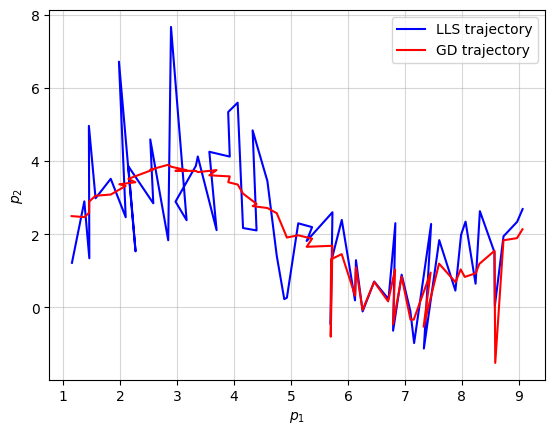

In [6]:
plt.plot(p_LLS_list[:, 0], p_LLS_list[:, 1], label="LLS trajectory", color="blue")
plt.plot(p_gd_list[:, 0], p_gd_list[:, 1], label="GD trajectory", color="red")
plt.grid(alpha=0.5)
plt.xlabel(r"$p_1$")
plt.ylabel(r"$p_2$")
plt.legend()